In [1]:
import sys
import utils as utils
from importlib import reload
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
reload(utils)
from tqdm import tqdm
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import plotting as plt_AMM

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (6, 4),
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
pylab.rcParams.update(params)
%config InlineBackend.figure_format = "retina"

import matplotlib
plt.rc('text', usetex=True)
plt.rc('text.latex', preamble=r'\usepackage{amsmath,amsfonts}')
dpi = 300

## Load parameters

In [5]:
import pickle

with open('data/params_env.pkl', 'rb') as f:
    params_env = pickle.load(f)

In [6]:
Nt = 10_000
T = 1.
S0 = 2820.
Z0 = S0
sigma_Binance = 0.0569 * S0  # we obtained this from market-milk daily volatility accessed 18 Dec 2024

tr_cost = 2e-7   # 10/100*0.01 * S0  # 10 bps

xi = 875 #567 for median or 875.0 for mean
fee = (100/100*0.02 * Z0) * xi  #CHANGED (100/100*0.01 * Z0) * xi 
a1= 142.712
a3= 13.568

kappaSQ = 316477600787601.7 * 10
Y0 = np.sqrt(kappaSQ / Z0)
eta = 1000 #CHANGED 50_000 #25589 * 3#1e4 #25589 * 3

params_env = {'sigma': sigma_Binance, 'S0': S0, 'Z0': Z0, 
              'Y0': Y0, 
              'eta': eta, 
              'xi': xi, 'T': T, 'a1': a1, 'a2': 1e-7, 'a3': a3, 'Nt': Nt,
              'fee': 0., 'feeV': fee, 'C': 0., 'gamma': 1e-10, 'zeta': 1e-10, 'tempLP': tr_cost, 'P0': 5e6} # gamma was 1e-8

In [7]:
params_env['P0'] = 4.5e6

## Define environment

In [8]:
env = utils.environment(**params_env)

In [9]:
mins_per_step = 24*60/10_000

In [10]:
np.random.seed(100)

nsims = 1_000
strag_LP = '1'
strag_vn = '1'

S, Y, Z, X, nu, wealth, perf, rew, venue_wealth, A_a_hist, A_b_hist, A_W_hist, A_B_hist, rew_drift_hist = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = True)

In [11]:
mins_per_step = 24*60/10_000
Nwindow = int(10/mins_per_step)

df = pd.DataFrame(data=np.concatenate((S.ravel().reshape(-1,1),Z.ravel().reshape(-1,1)),axis=1), columns=('S','Z'))
df['difference'] = df['S'] - df['Z']
diffs = df['difference'].rolling(Nwindow).mean()
diffs.dropna(inplace=True)

In [12]:
keepNumber = int(24*60/10)
diffs = diffs.iloc[::keepNumber]

In [13]:
fs = 14
fsL = 19
plt.rcParams["font.size"] = fs

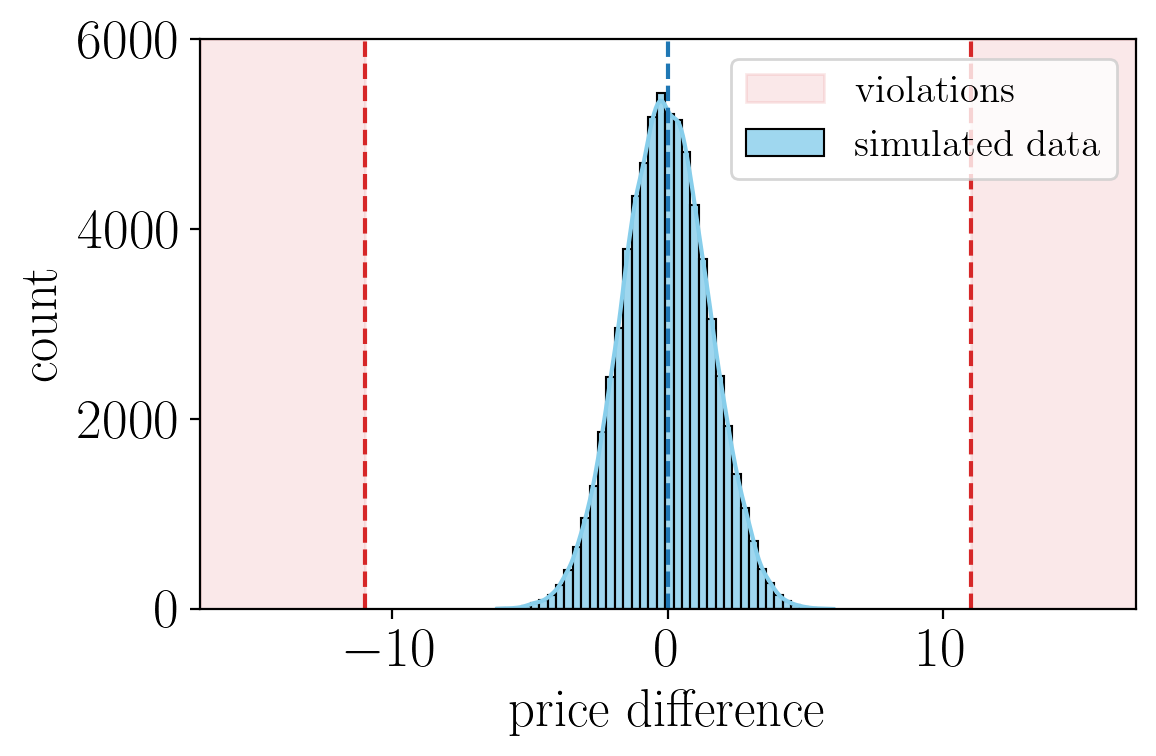

In [14]:
import seaborn as sns
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

x = -10.994492750981774

sns.histplot(data=diffs, bins=40, kde=True, color="skyblue", label = r'$\mathrm{simulated}$ $\mathrm{data}$', ax=axs, alpha =0.8)
axs.set_xlabel(r'$\mathrm{price\,\,difference}$', fontsize = fsL)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = fsL)

axs.axvline(0,linestyle = '--', color='tab:blue')
axs.axvline(x,linestyle = '--', color='tab:red')
axs.axvline(-x,linestyle = '--', color='tab:red')

xmin = -17
xmax = 17
ymax = 6_000

xaux_left = np.linspace(xmin, x, 100)
xaux_right = np.linspace(-x, xmax, 100)

axs.fill_between(xaux_left, ymax*np.ones_like(xaux_left), color = 'tab:red' , alpha=0.1, label= r'$\mathrm{violations}$')
axs.fill_between(xaux_right, ymax*np.ones_like(xaux_right), color = 'tab:red' , alpha=0.1)

plt.ylim([0,ymax])
plt.tight_layout()
plt.xlim([xmin,xmax])
plt.legend(fontsize=fs)

plt.tight_layout()
plt.savefig('figures/negative-intensity-regions-symm-simulations.pdf', format="pdf", dpi=dpi)
plt.show()

In [15]:
qtl_Y = np.zeros((len(env.timesteps),3))
qtl_nu = np.zeros((len(env.timesteps),3))
qtl_rew = np.zeros((len(env.timesteps),3))
qtl_Z = np.zeros((len(env.timesteps),3))
qtl_S = np.zeros((len(env.timesteps),3))

for it, t in enumerate(env.timesteps):
    qtl_Y[it, :] = np.quantile(Y[it,:],[0.05,0.5,0.95],axis=0)
    qtl_nu[it, :] = np.quantile(nu[it,:],[0.05,0.5,0.95],axis=0)
    qtl_rew[it, :] = np.quantile(rew[it,:],[0.05,0.5,0.95],axis=0)
    qtl_Z[it, :] = np.quantile(Z[it,:],[0.05,0.5,0.95],axis=0)
    qtl_S[it, :] = np.quantile(S[it,:],[0.05,0.5,0.95],axis=0)

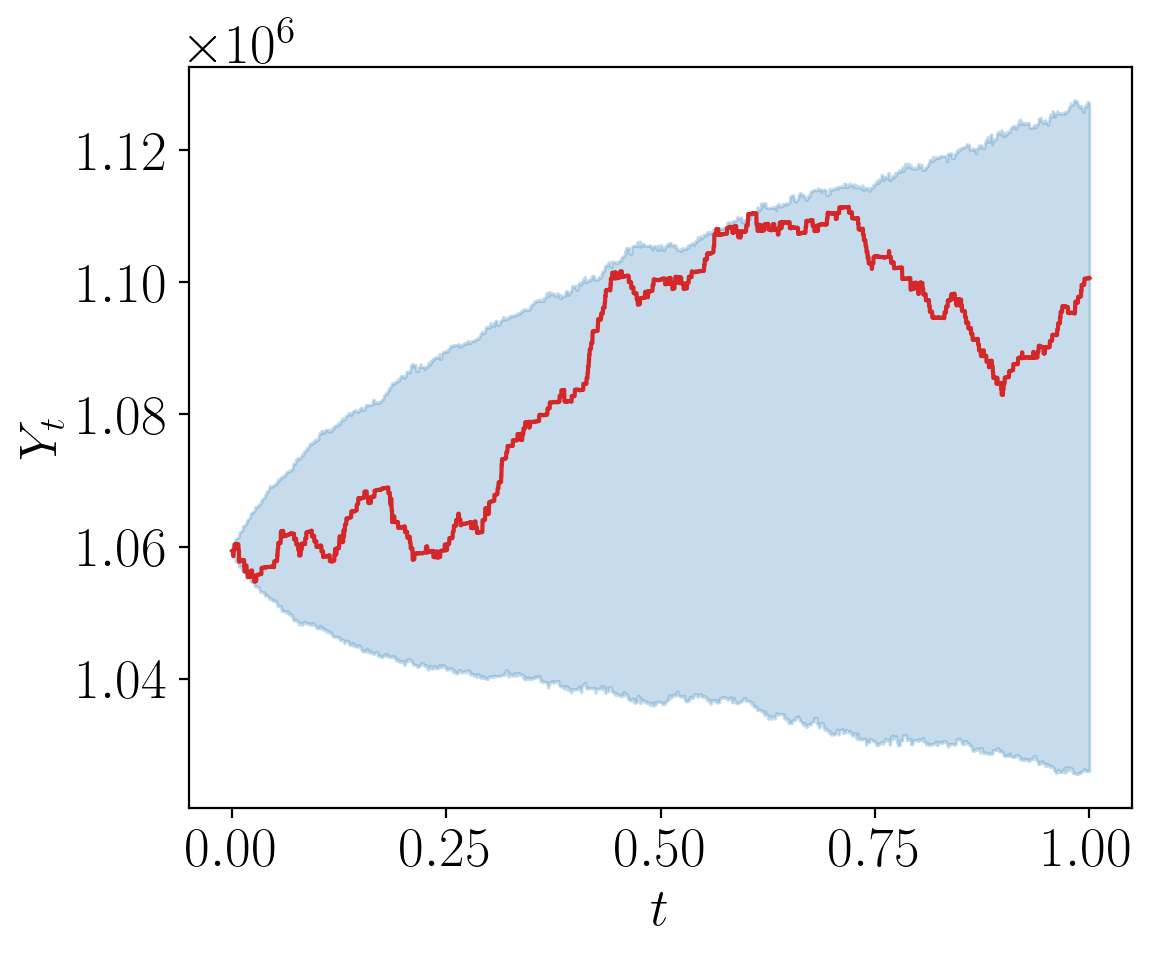

In [16]:
nsim = 53

fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, Y[:,nsim], label=r'$Y$', color ='tab:red')
plt.fill_between(env.timesteps,qtl_Y[:,0],qtl_Y[:,-1], color='tab:blue', alpha=0.25)
plt.xlabel(r'$t$', fontsize = fsL)
plt.ylabel(r'$Y_t$', fontsize = fsL)
plt.tight_layout()
plt.savefig('figures/baseline-sim-Y-paths.pdf', format="pdf", dpi=dpi)
plt.show()

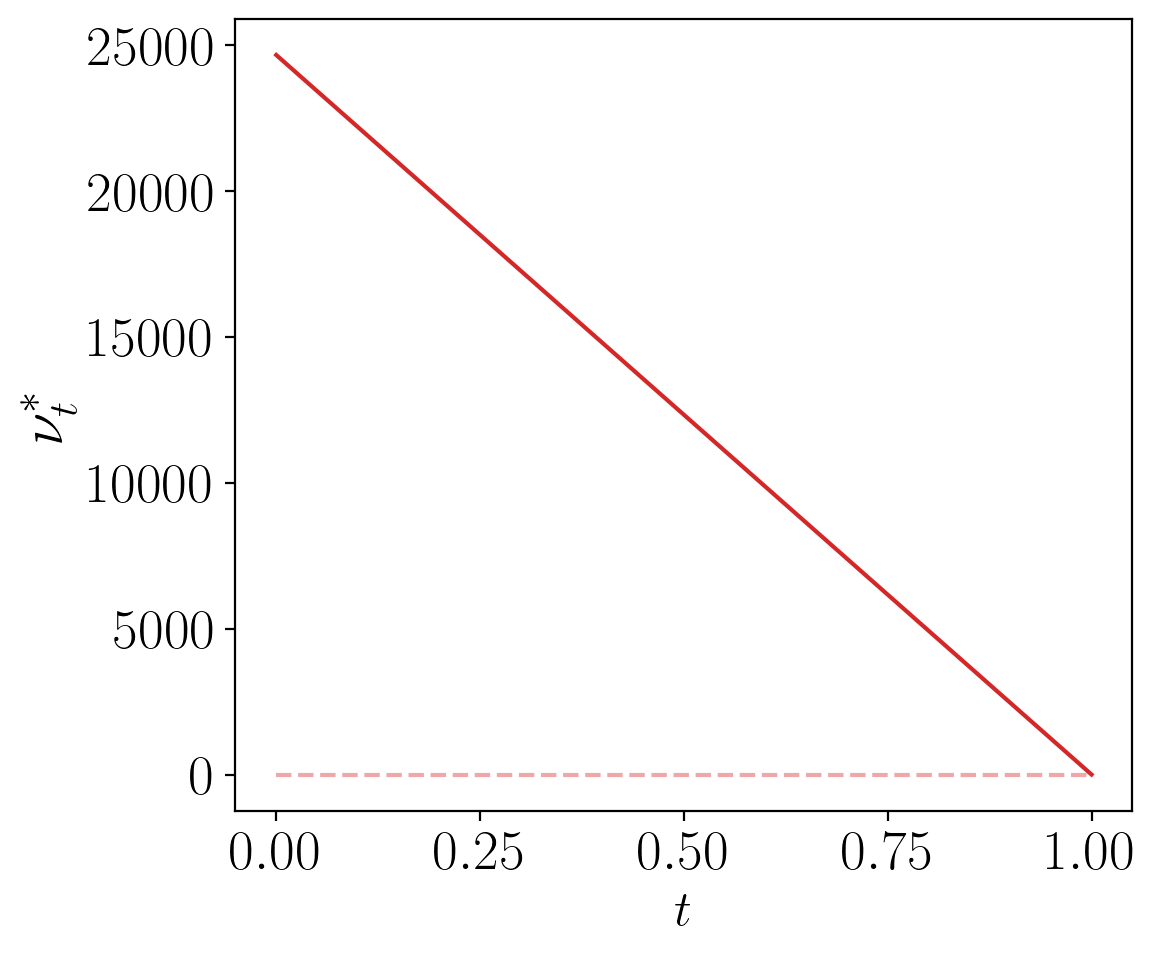

In [17]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, nu[:,nsim], label=r'$\nu$', color ='tab:red')
plt.fill_between(env.timesteps,qtl_nu[:,0],qtl_nu[:,-1], color='tab:blue', alpha=0.25)
plt.xlabel(r'$t$', fontsize = 18)
plt.ylabel(r'$\nu^*_t$', fontsize = 22)
plt.hlines(y = 0, xmin = 0, xmax = 1, linestyle = '--', alpha = 0.4, color='tab:red')
plt.tight_layout()
plt.savefig('figures/baseline-sim-nu-paths.pdf', format="pdf", dpi=dpi)
plt.show()

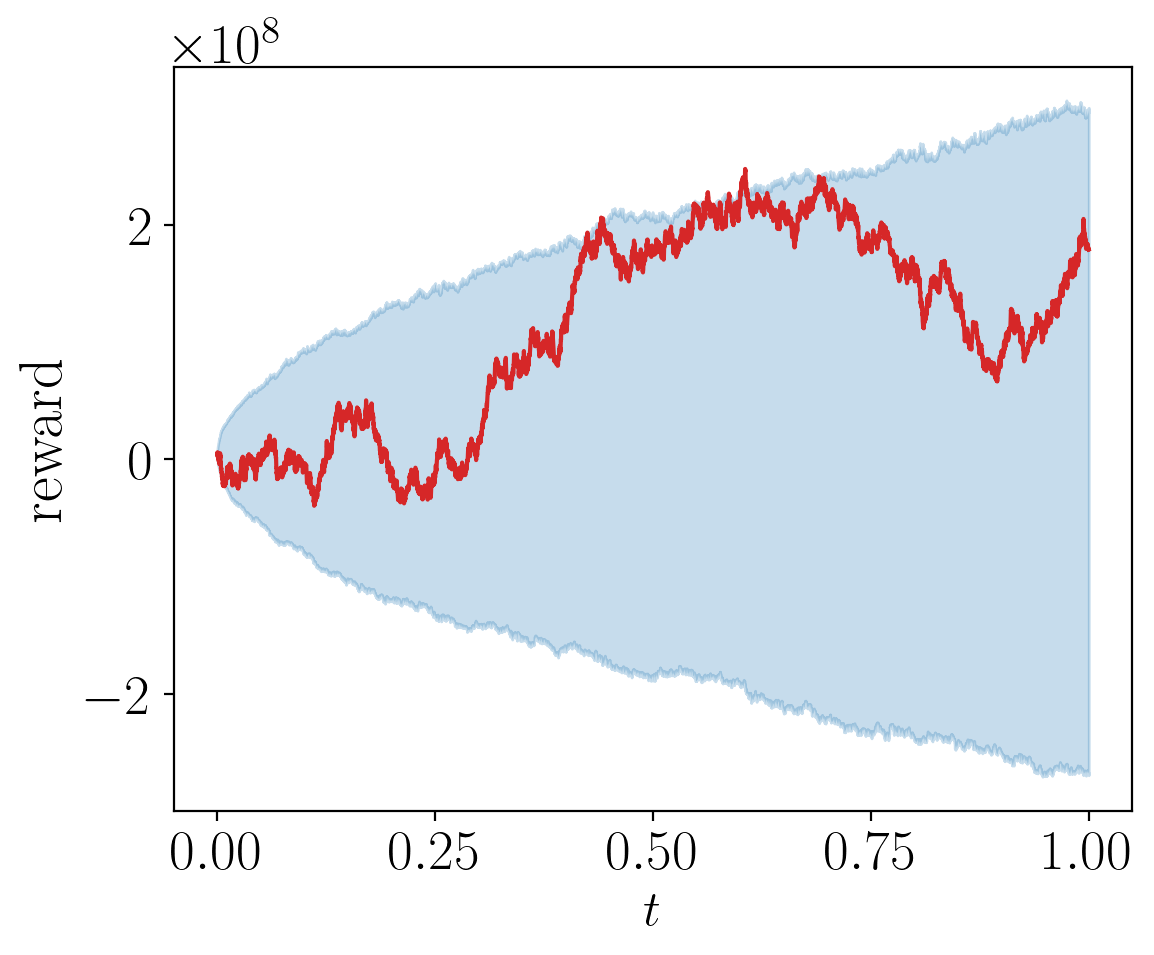

In [18]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, rew[:,nsim], label='reward', color ='tab:red')
plt.fill_between(env.timesteps,qtl_rew[:,0],qtl_rew[:,-1], color='tab:blue', alpha=0.25)
plt.xlabel(r'$t$', fontsize = 18)
plt.ylabel(r'$\mathrm{reward}$', fontsize = 22)
plt.tight_layout()
plt.savefig('figures/baseline-sim-rew-paths.pdf', format="pdf", dpi=dpi)
plt.show()

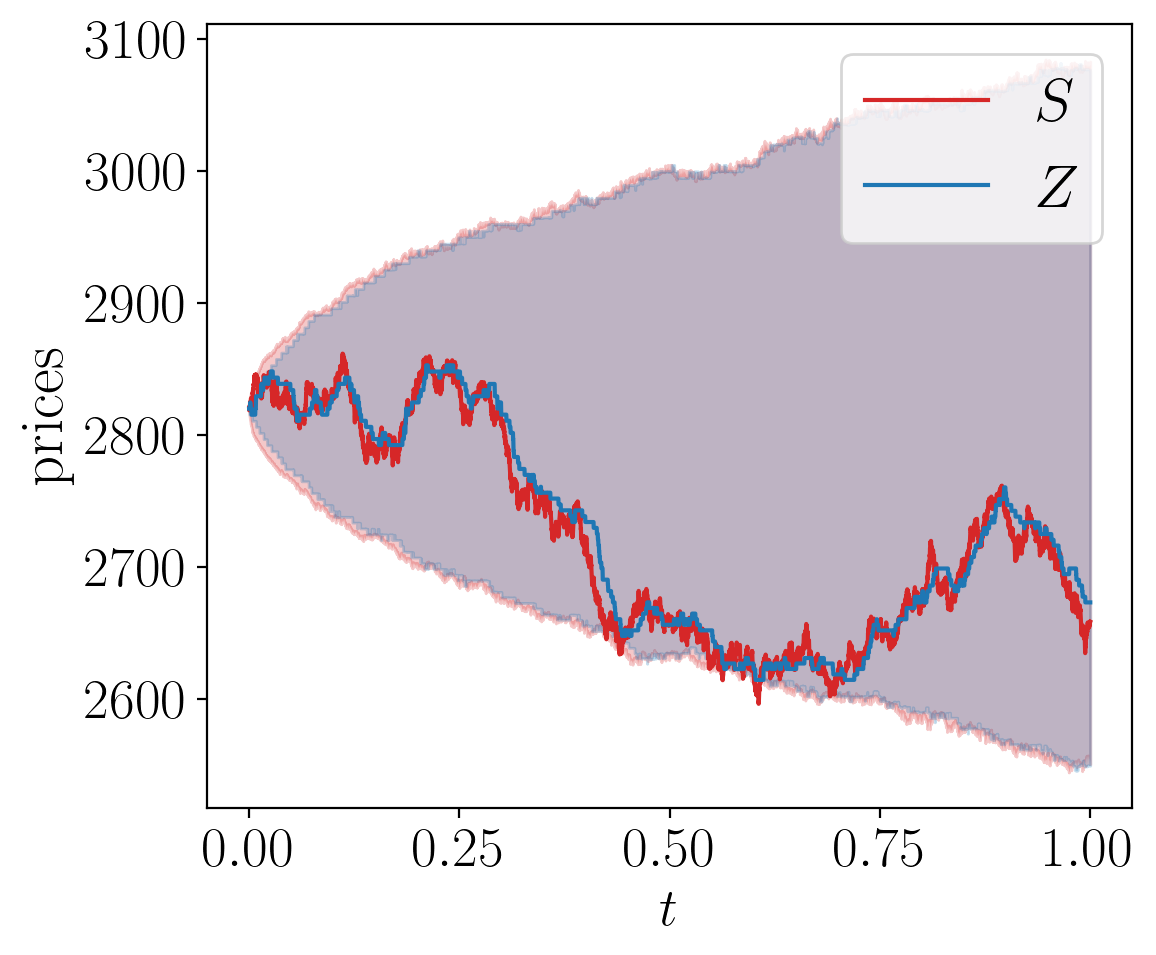

In [19]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, S[:,nsim], label=r'$S$', color ='tab:red')
plt.plot(env.timesteps, Z[:,nsim], label=r'$Z$', color ='tab:blue')

plt.fill_between(env.timesteps,qtl_S[:,0],qtl_S[:,-1], color='tab:red', alpha=0.25)
plt.fill_between(env.timesteps,qtl_Z[:,0],qtl_Z[:,-1], color='tab:blue', alpha=0.25)

plt.xlabel(r'$t$', fontsize = fsL)
plt.ylabel(r'$\mathrm{prices}$', fontsize = fsL+3)
plt.legend(fontsize = fsL+3)
plt.tight_layout()
plt.savefig('figures/baseline-sim-S-Z-paths.pdf', format="pdf", dpi=dpi)
plt.show()

In [20]:
reload(plt_AMM)

<module 'plotting' from '/Users/leandrosb/Documents/GitHub/amm-make-take-fee/plotting.py'>

In [21]:
values = [1,2,4,8,16]
colors = ['tab:red', 'tab:orange', 'skyblue', 'tab:green', 'tab:blue']

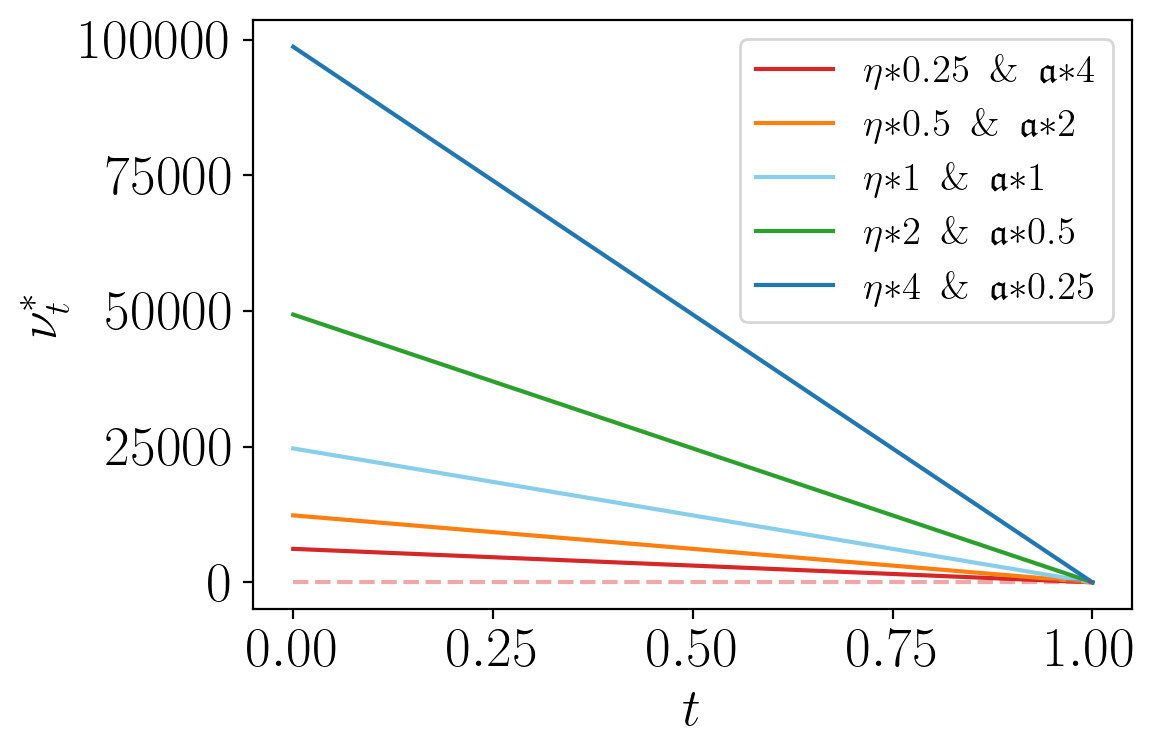

In [22]:
values1 = [1/4, 1/2, 1,2,4]
values2 = [4,2, 1,1/2,1/4]
plt_AMM.stress_two_parameters_two_sets_and_show_nu(parameter1 = 'eta', parameter2 ='tempLP', values1 = values1, values2 = values2, params = params_env,
                                                   to_print1 =r'$\eta$', to_print2 = r'$\mathfrak{a}$', logScale = False, colors = colors,
                                                  savefig = True, filename = 'stress-eta-tempLP')

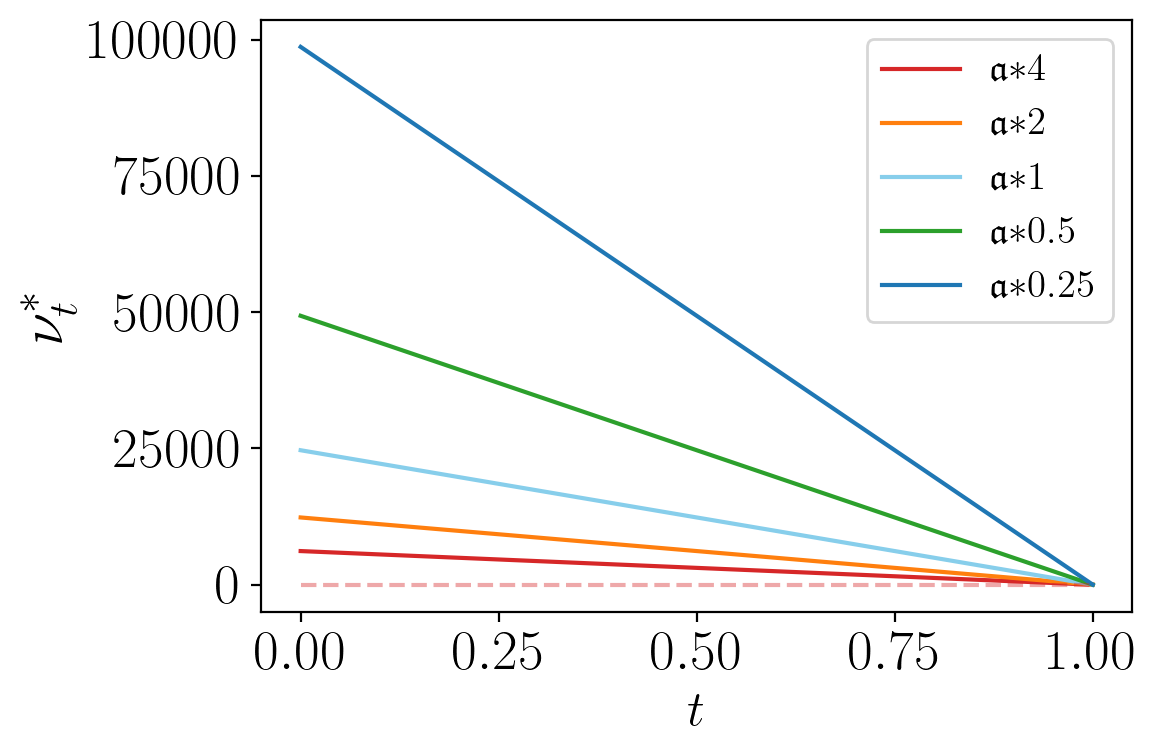

In [23]:
plt_AMM.stress_parameter_and_show_nu(parameter = 'tempLP', values=values2,  params=params_env, 
                                     savefig = True, filename = 'stress-tempLP', to_print=r'$\mathfrak{a}$')

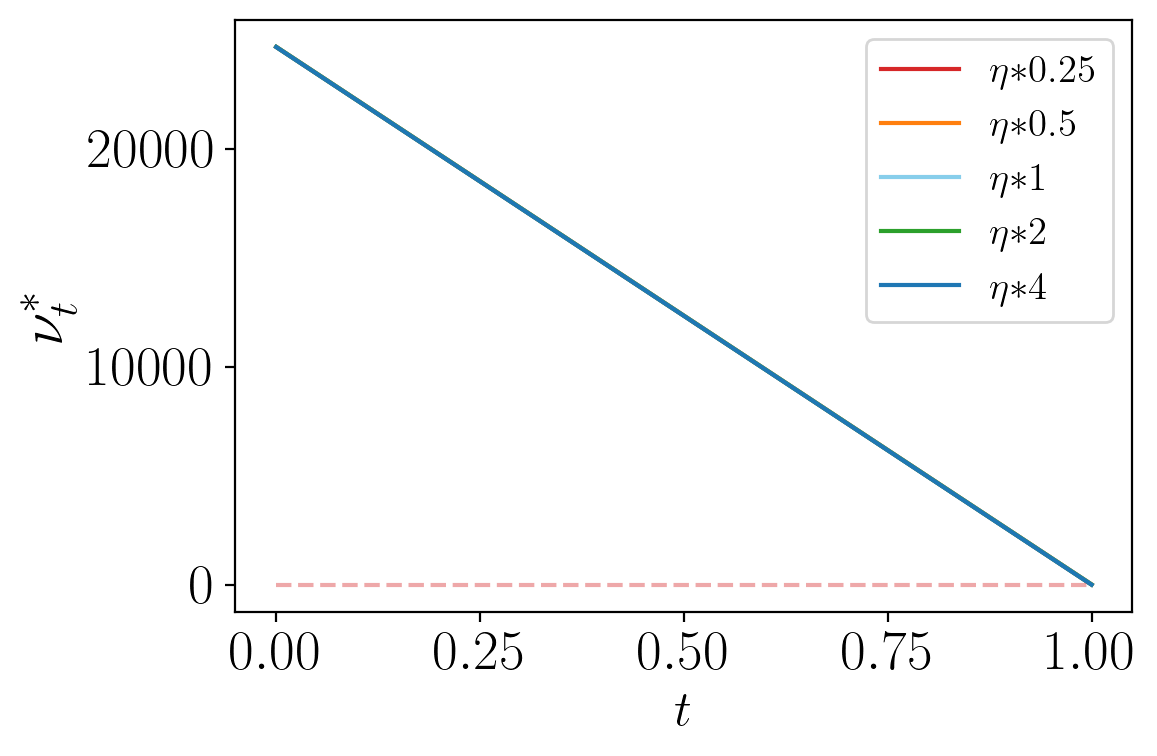

In [24]:
plt_AMM.stress_parameter_and_show_nu(parameter = 'eta', values = values1, params=params_env, to_print=r'$\eta$',
                                     savefig = True, filename = 'stress-eta')

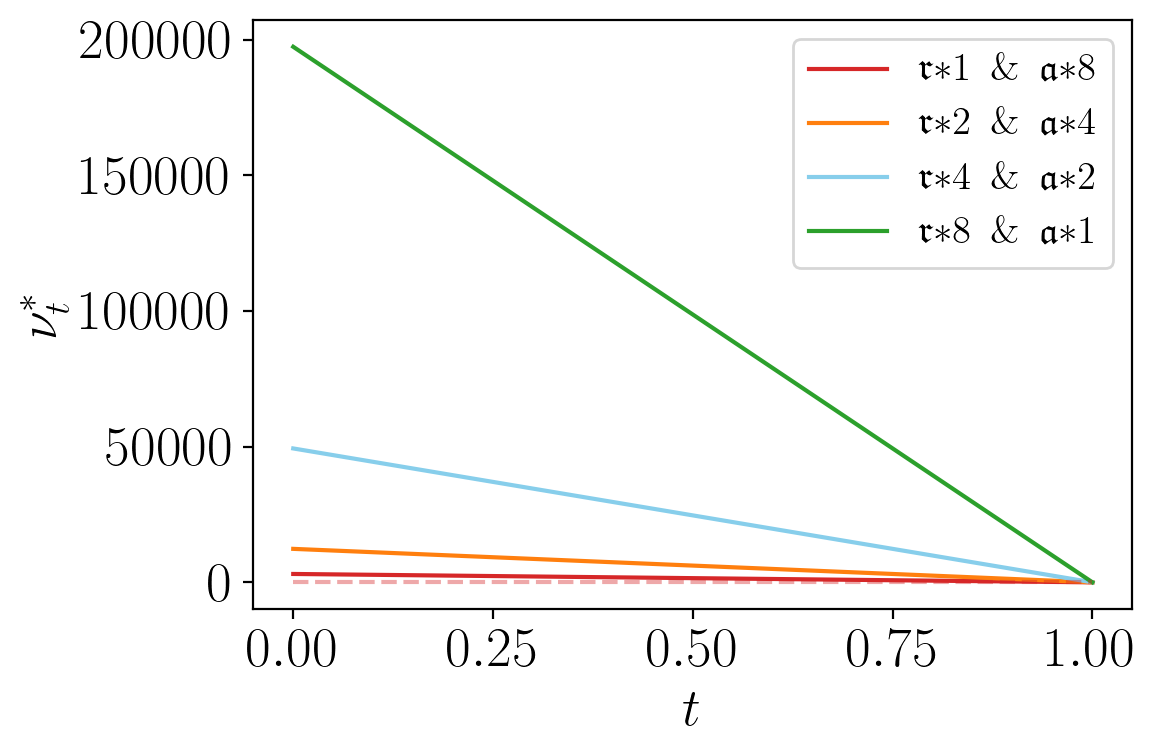

In [25]:
values1 = [1,2,4,8]
values2 = [8,4,2,1]
plt_AMM.stress_two_parameters_two_sets_and_show_nu(parameter1 = 'feeV',parameter2 =  'tempLP', values1 = values1, values2 = values2, params=params_env,
                                                   to_print1 ='$\mathfrak{r}$', to_print2 = r'$\mathfrak{a}$', logScale = False, 
                                                  savefig = True, filename = 'stress-feeV-tempLP')

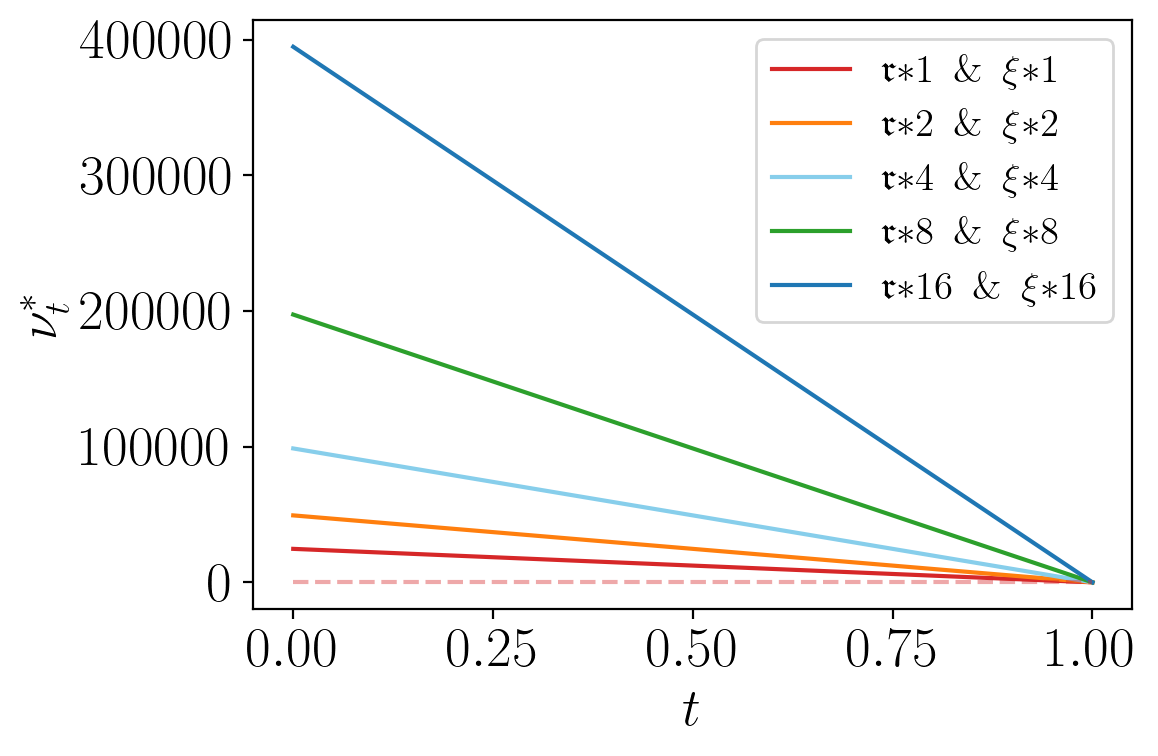

In [26]:
plt_AMM.stress_two_parameters_two_sets_and_show_nu(parameter1 = 'feeV', parameter2 =  'xi', values1 = values, values2 = values, params=params_env,
                                                   to_print1 ='$\mathfrak{r}$', to_print2 = r'$\xi$',
                                                  savefig = True, filename = 'stress-feeV-xi')

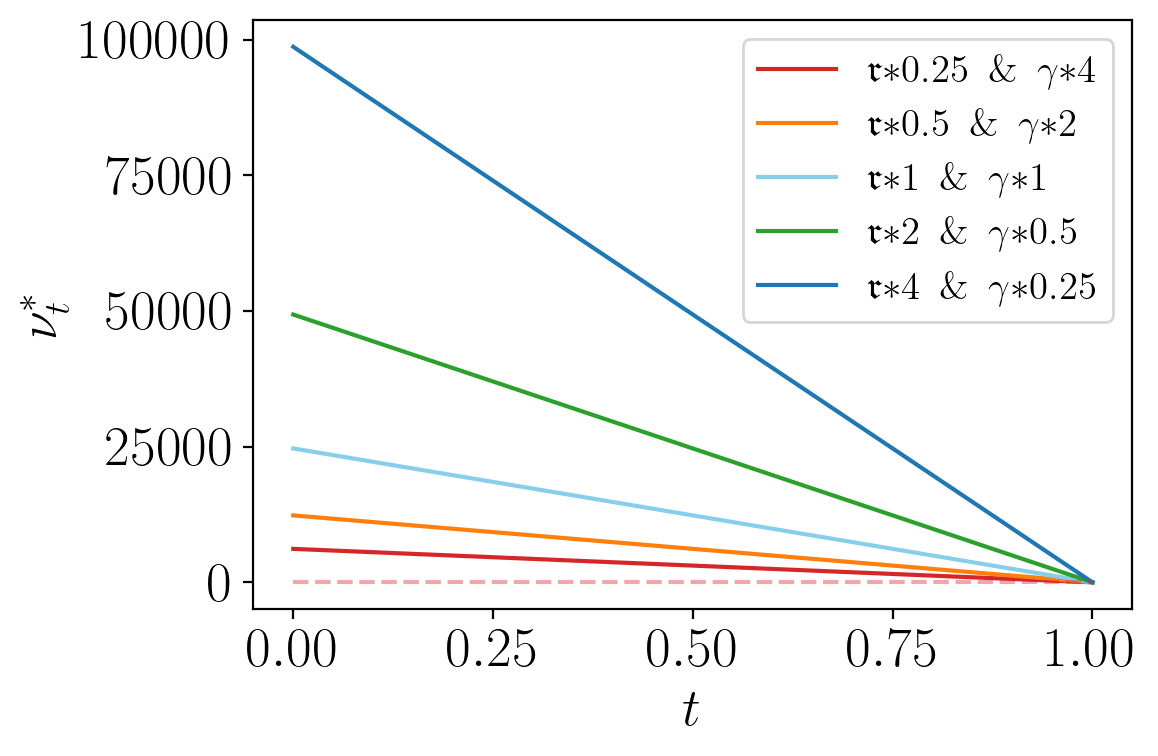

In [27]:
values1 = [1/4, 1/2, 1,2,4]
values2 = [4,2, 1,1/2,1/4]
plt_AMM.stress_two_parameters_two_sets_and_show_nu(parameter1 = 'feeV', parameter2 = 'gamma', values1 = values1, values2 = values2, params=params_env,
                                                   to_print1 =r'$\mathfrak{r}$', to_print2 = r'$\gamma$',
                                                  savefig = True, filename = 'stress-feeV-gamma')

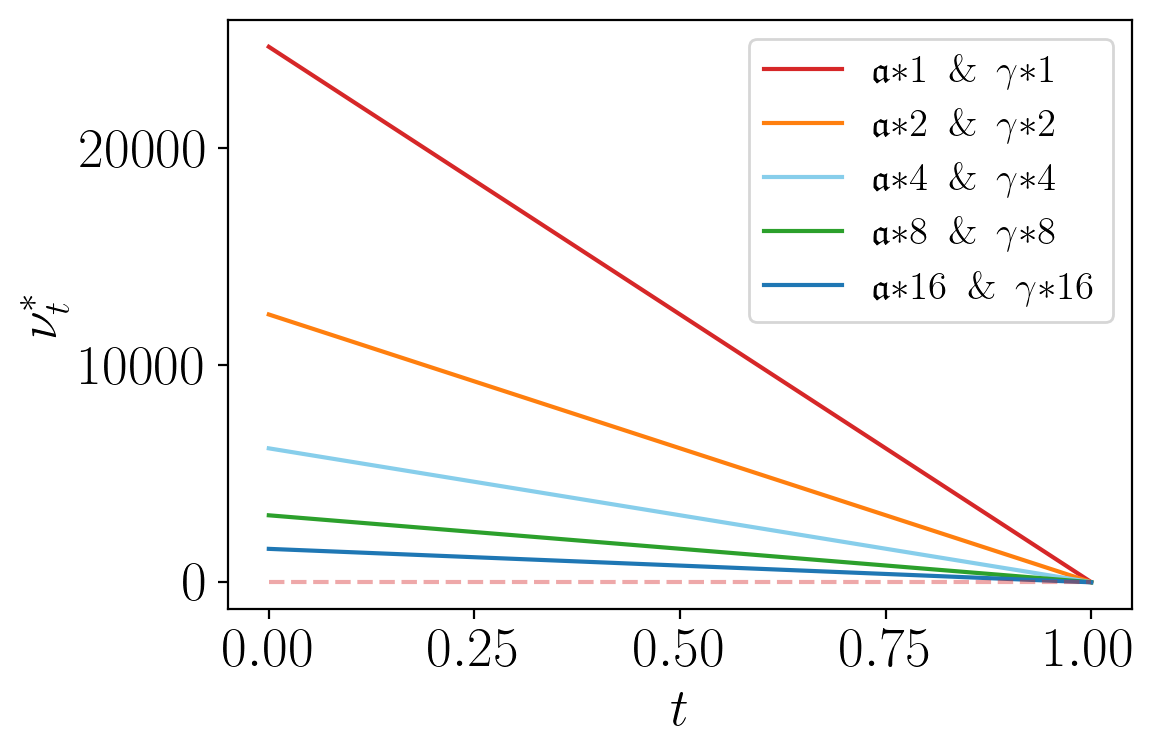

In [28]:
plt_AMM.stress_two_parameters_two_sets_and_show_nu(parameter1 = 'tempLP', parameter2 = 'gamma', values1 = values, values2 = values, params=params_env,
                                                   to_print1 =r'$\mathfrak{a}$', to_print2 = r'$\gamma$',
                                                  savefig = True, filename = 'stress-tempLP-gamma')

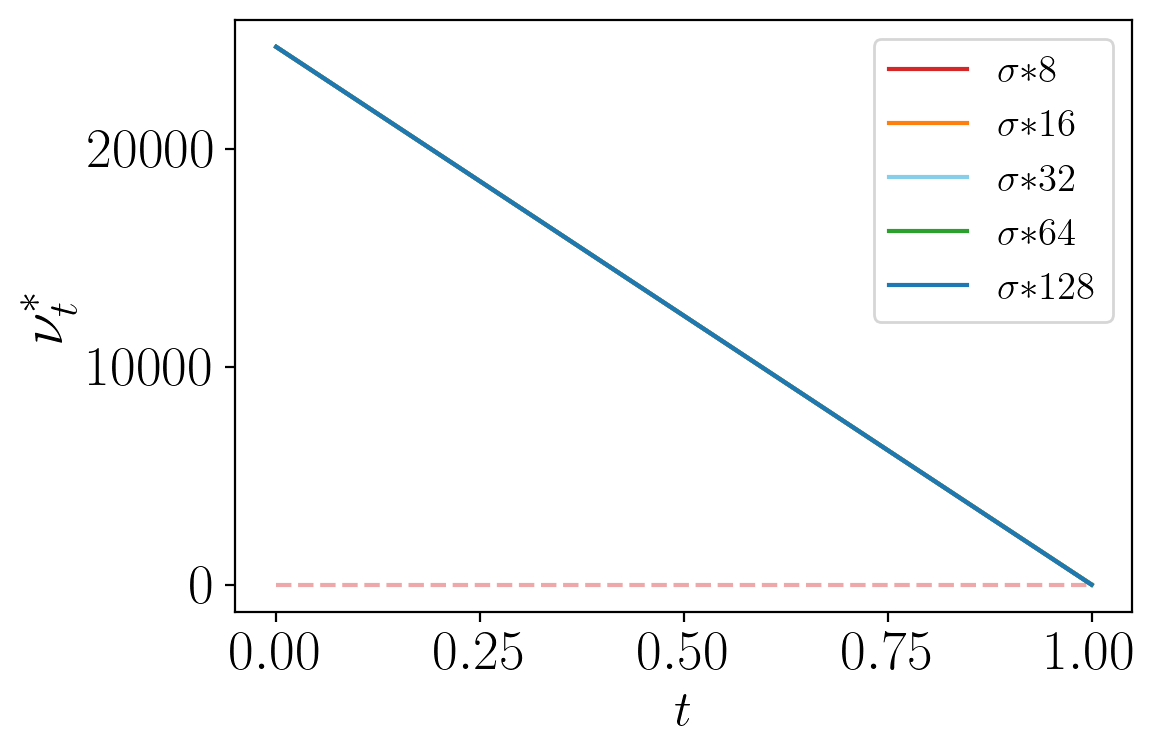

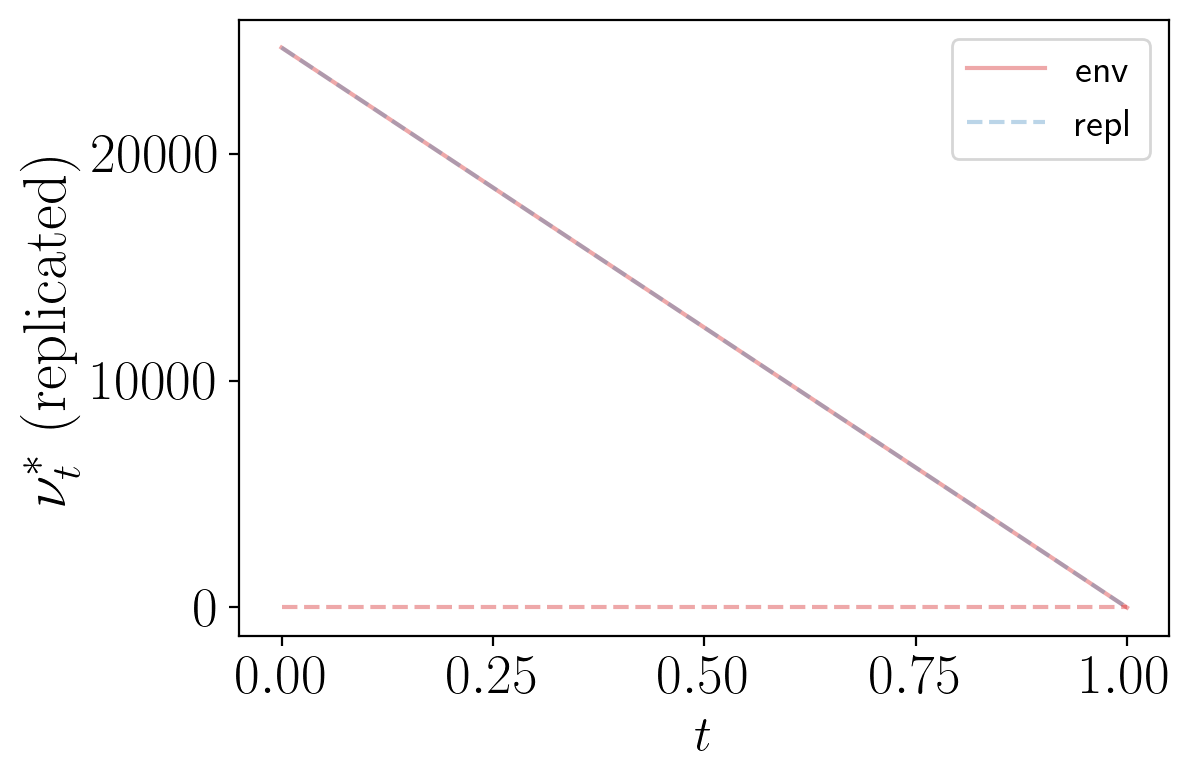

In [29]:
plt_AMM.stress_parameter_and_show_nu(parameter = 'sigma', values = [8,16,32,64,128], to_print=r'$\sigma$', params=params_env,
                                    savefig = True, filename = 'stress-sigma', verbose = True)

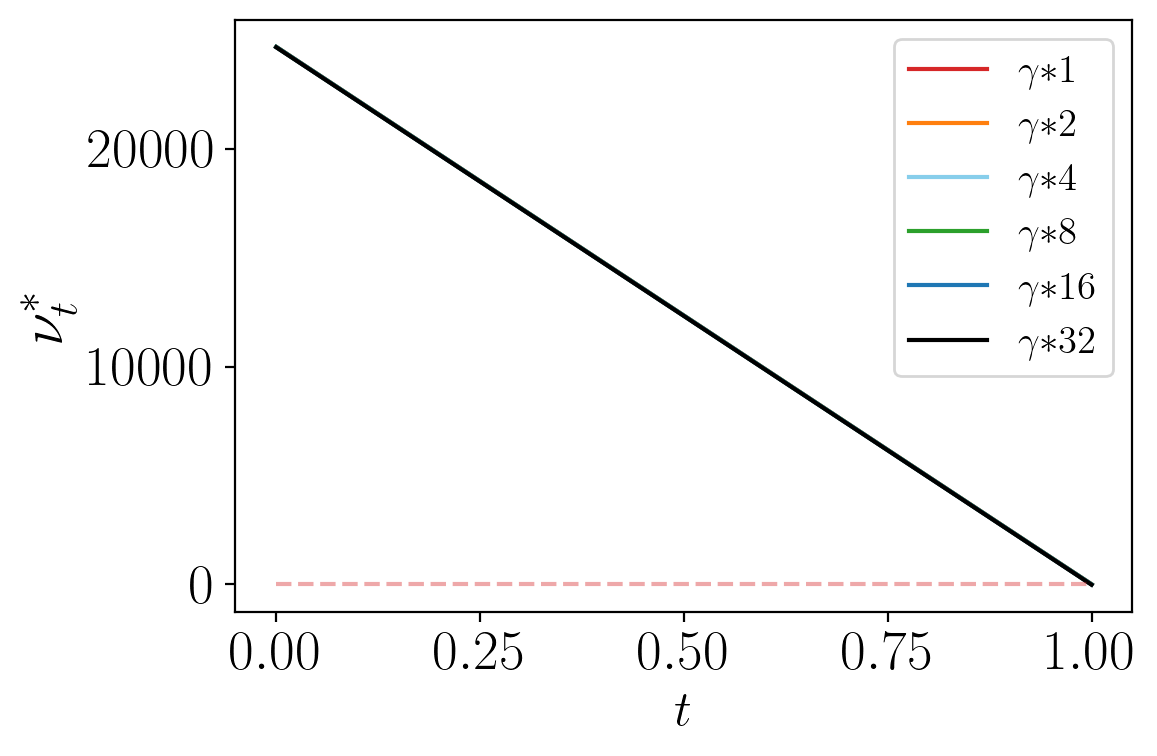

In [30]:
plt_AMM.stress_parameter_and_show_nu(parameter = 'gamma', values = [1,2,4,8,16,32],params=params_env, to_print=r'$\gamma$',
                                     savefig = True, filename = 'stress-gamma')

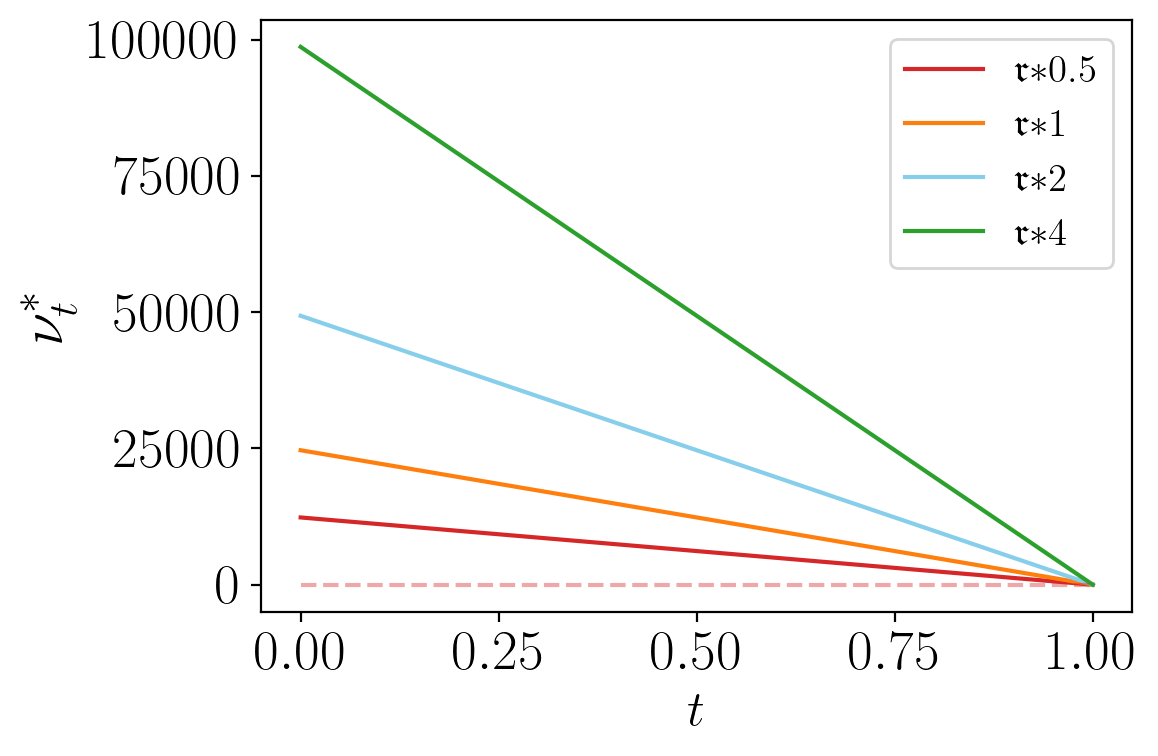

In [31]:
plt_AMM.stress_parameter_and_show_nu(parameter = 'feeV', values = [0.5,1,2,4], params=params_env, to_print=r'$\mathfrak{r}$',
                                     savefig = True, filename = 'stress-feeV')

# Performance of LPs and Venue

In [32]:
nsims = 10_000
strag_LP = '1'
strag_vn = '1'
S, Y, Z, X, nu, wealth, perf, rew, venue_wealth, A_a_hist, A_b_hist, A_W_hist, A_B_hist, rew_drift_hist = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = True)

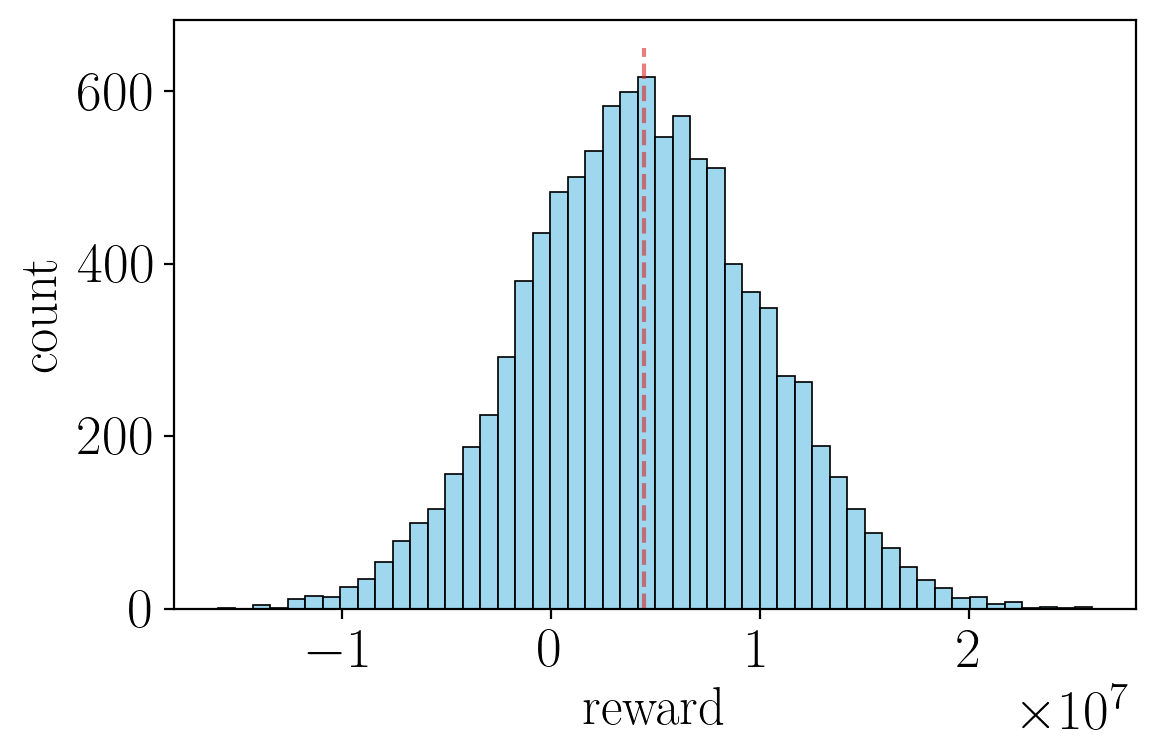

In [33]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

sns.histplot(data=wealth[-1,:], bins = 50, kde=False, color="skyblue",  ax=axs, alpha =0.8)
plt.vlines(x = np.mean(wealth[-1,:]), ymin=0,ymax=650, linestyle='--', color='tab:red', alpha =0.6)
axs.set_xlabel(r'$\mathrm{reward}$', fontsize = fsL)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = fsL)
plt.tight_layout()
plt.savefig('figures/hist-sim-wealth-LP.pdf', format="pdf", dpi=dpi)
plt.show()

In [34]:
np.mean(wealth[-1,:])

4451908.852210312

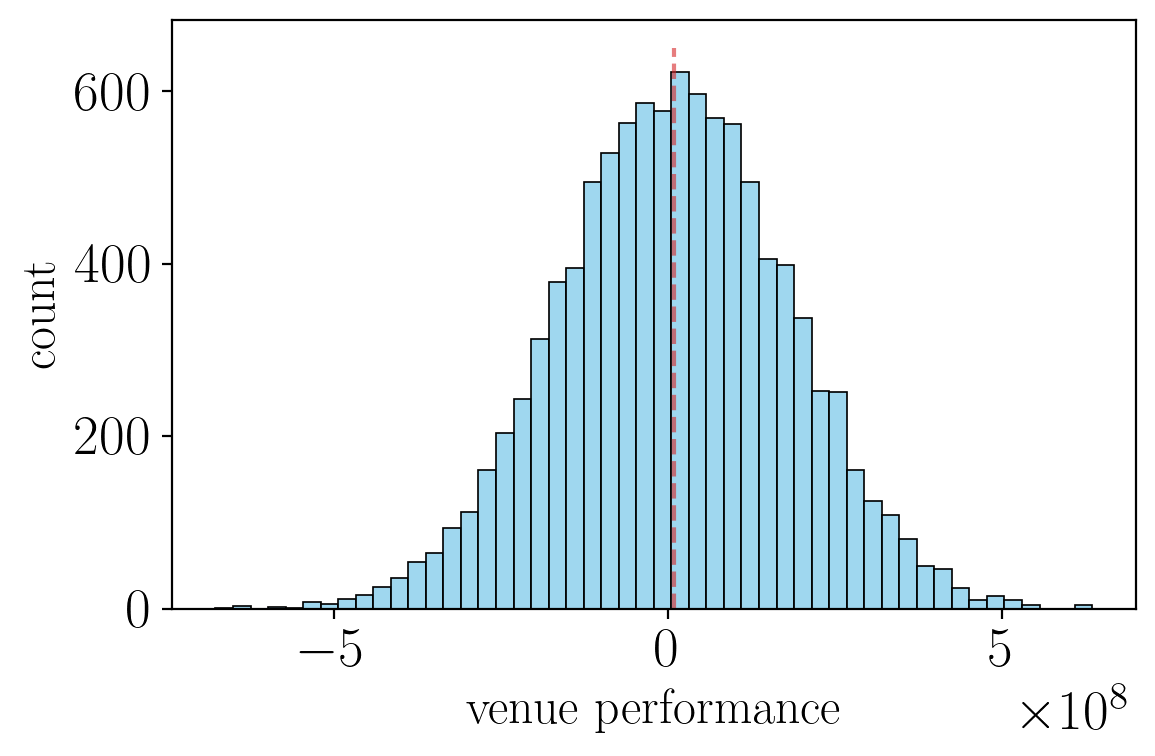

In [35]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

sns.histplot(data=venue_wealth[0,:], bins = 50, kde=False, color="skyblue",  ax=axs, alpha =0.8)
plt.vlines(x = np.mean(venue_wealth[0,:]), ymin=0,ymax=650, linestyle='--', color='tab:red', alpha =0.6)

axs.set_xlabel(r'$\mathrm{venue~performance}$', fontsize = 18)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = 18)
plt.tight_layout()
plt.savefig('figures/hist-venue-perf.pdf', format="pdf", dpi=dpi)
plt.show()

In [36]:
np.mean(venue_wealth[0,:])

9479338.174004778

In [37]:
print(f'Venue\'s expected performance (LQ utility): {venue_wealth[0,:].mean():1.5f}')

Venue's expected performance (LQ utility): 9479338.17400


In [38]:
np.exp(-env.gamma*env.P0)

0.9995501012348142

In [39]:
np.mean(wealth[0,:])/ np.mean(venue_wealth[0,:])

0.469643425573612

In [40]:
(np.mean(venue_wealth[0,:]) - np.mean(wealth[0,:]) ) / 2

2513714.660897233

In [41]:
params_env['P0'] + -549687.629114496

3950312.370885504

In [42]:
## P0 = 4.5e6

In [43]:
(np.mean(venue_wealth[0,:]) + np.mean(wealth[0,:]))/2 - np.mean(wealth[0,:]) #+ params_env['P0']

2513714.6608972335

In [44]:
import scipy as scipy

In [45]:
#x = np.random.randn(1_000_000,)
#scipy.stats.ttest_1samp(x, popmean=0.)

In [46]:
scipy.stats.ttest_1samp(wealth[0,:], popmean=0.)

TtestResult(statistic=79.44789396734089, pvalue=0.0, df=9999)

In [47]:
scipy.stats.ttest_1samp(venue_wealth[0,:], popmean=0.)

TtestResult(statistic=5.536109040776982, pvalue=3.170777233233872e-08, df=9999)

# LP does not trade

In [48]:
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (6, 4),
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
pylab.rcParams.update(params)
%config InlineBackend.figure_format = "retina"

import matplotlib
plt.rc('text', usetex=True)
plt.rc('text.latex', preamble=r'\usepackage{amsmath,amsfonts}')
dpi = 300

In [49]:
np.random.seed(100)

In [50]:
nsims = 1_000
strag_LP = '0'
strag_vn = '1'

S, Y, Z, X, nu, wealth, perf, rew, venue_wealth = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = False)

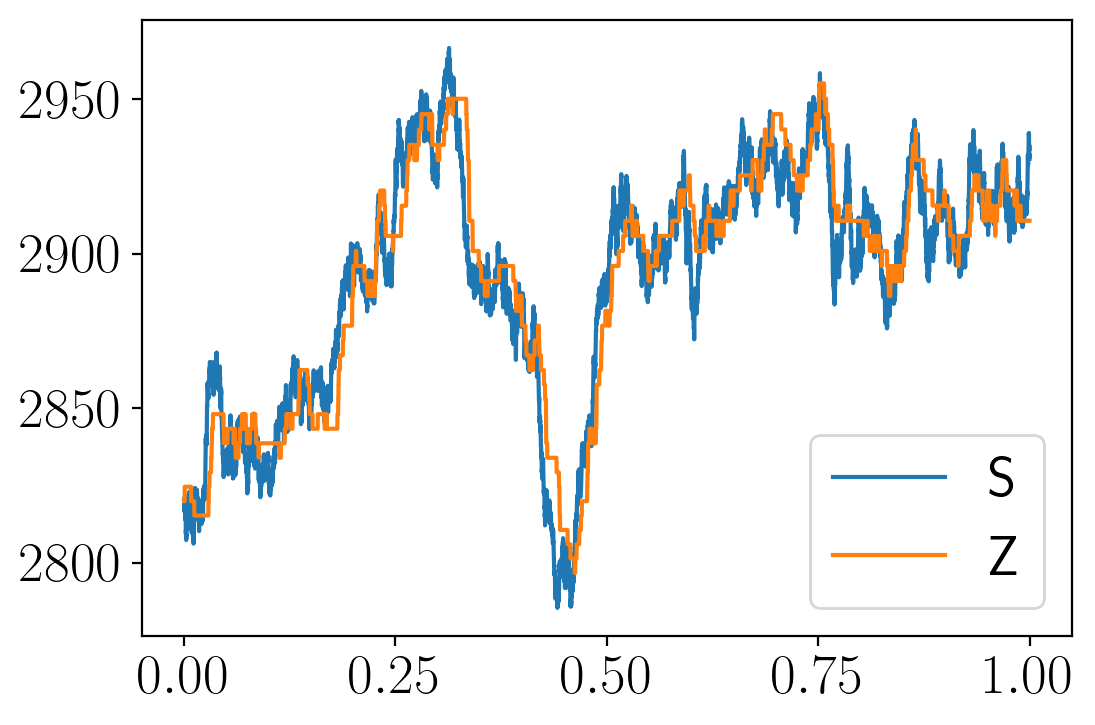

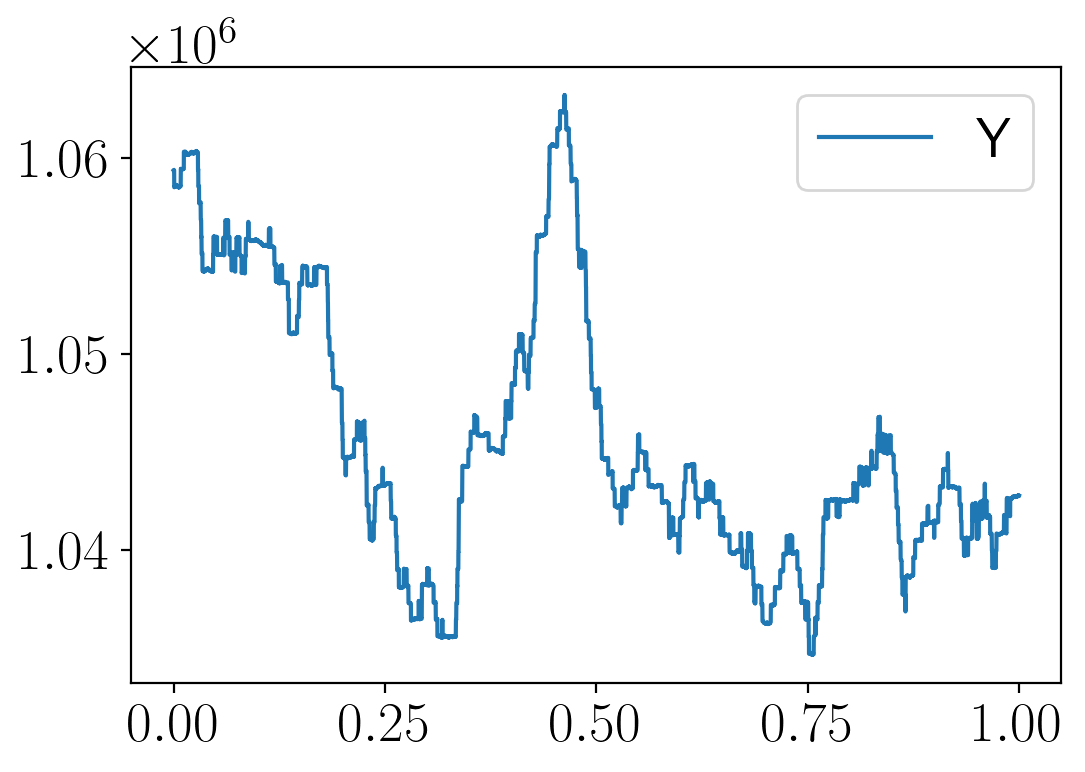

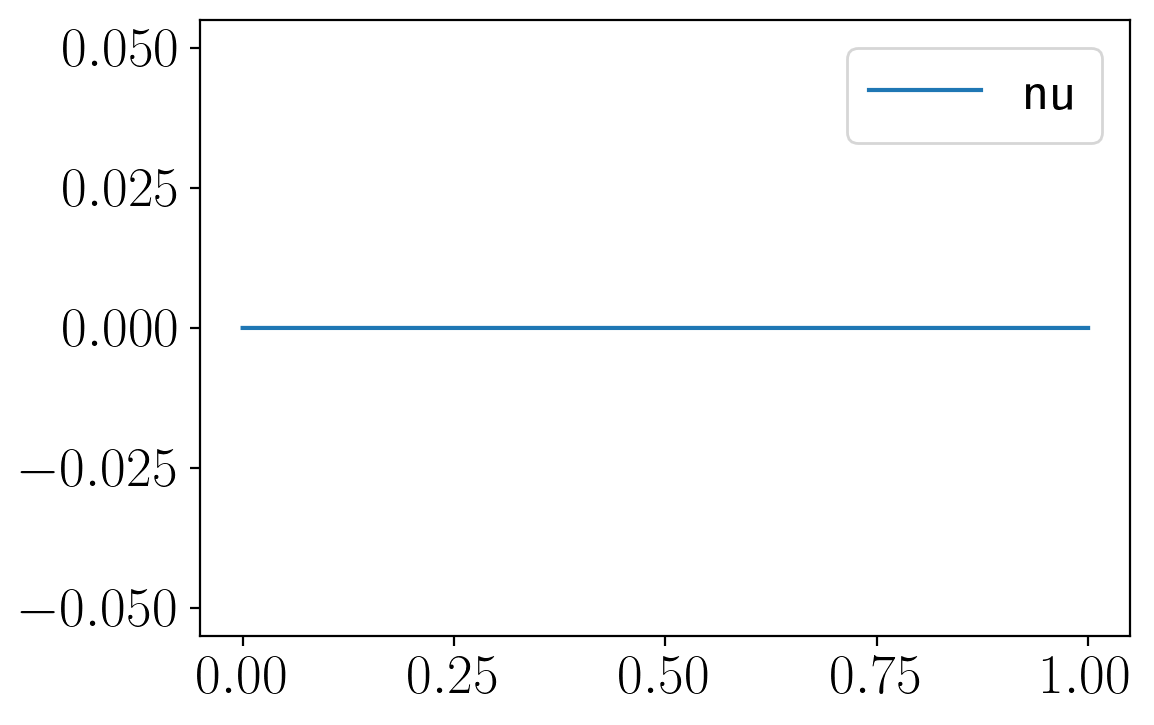

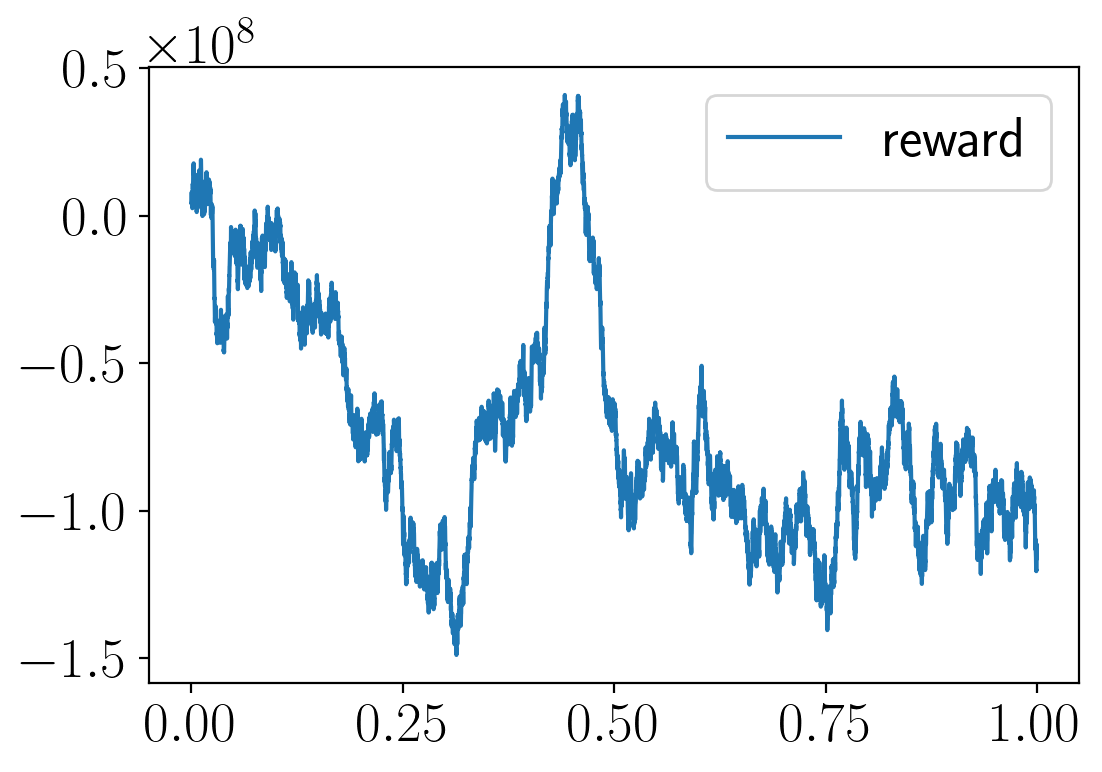

In [51]:
num_sim = 58

plt.plot(env.timesteps, S[:,num_sim], label='S')
plt.plot(env.timesteps, Z[:,num_sim], label='Z')
plt.legend()
plt.show()

plt.plot(env.timesteps, Y[:,num_sim], label='Y')
plt.legend()
plt.show()

plt.plot(env.timesteps, nu[:,num_sim], label='nu')
plt.legend()
plt.show()


plt.plot(env.timesteps, rew[:,num_sim], label='reward')
plt.legend()
plt.show()

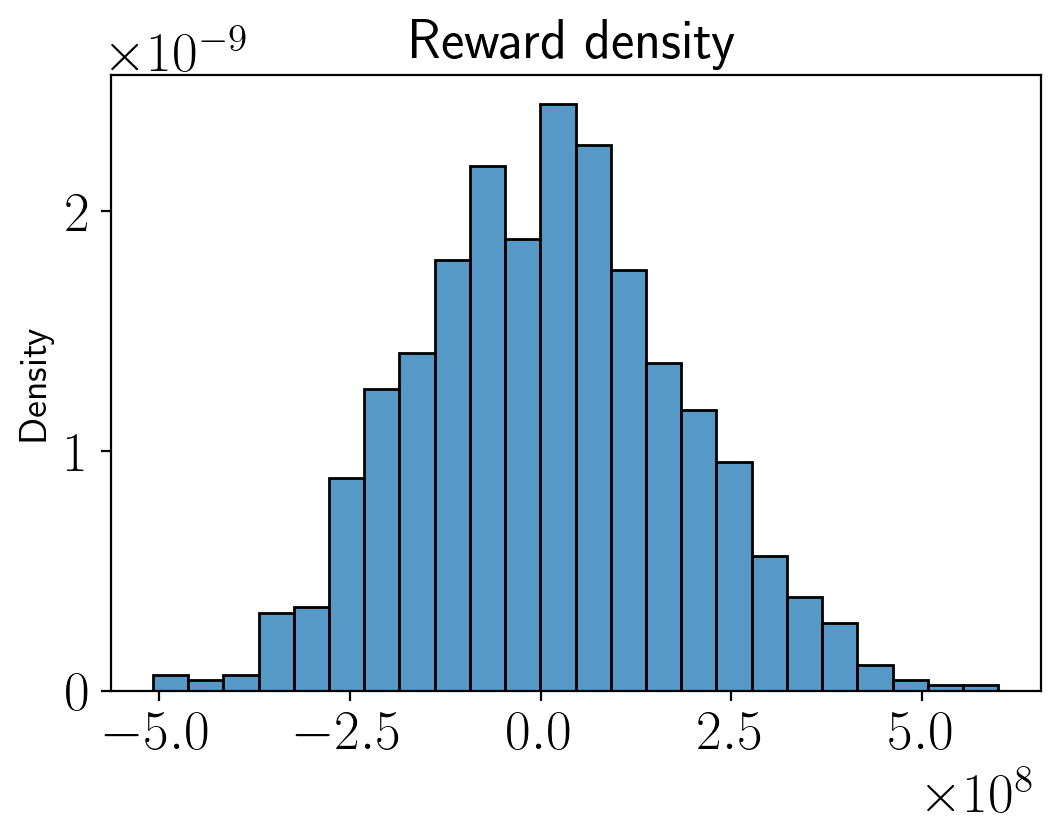

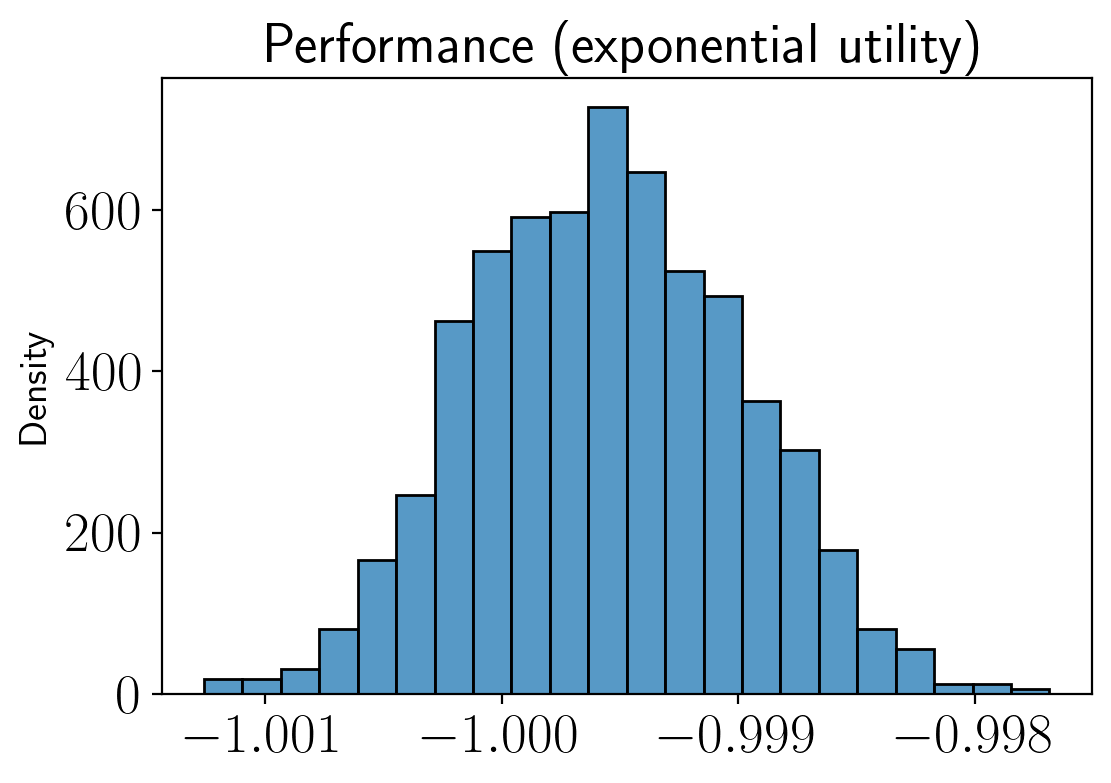

LP's expected performance (exponential utility, strag_LP:0, strag_vn:1): -0.99956
LP's expected wealth: 4446892.86670
Expected reward: 9343474.56016


In [52]:
sns.histplot(rew[-1,:], stat='density')
plt.title("Reward density")
plt.show()

sns.histplot(perf[0,:], stat='density')
plt.title("Performance (exponential utility)")
plt.show()

print(f'LP\'s expected performance (exponential utility, strag_LP:{strag_LP}, strag_vn:{strag_vn}): {perf[0,:].mean():1.5f}')
print(f'LP\'s expected wealth: {wealth[0,:].mean():1.5f}')
print(f'Expected reward: {rew[-1,:].mean():1.5f}')

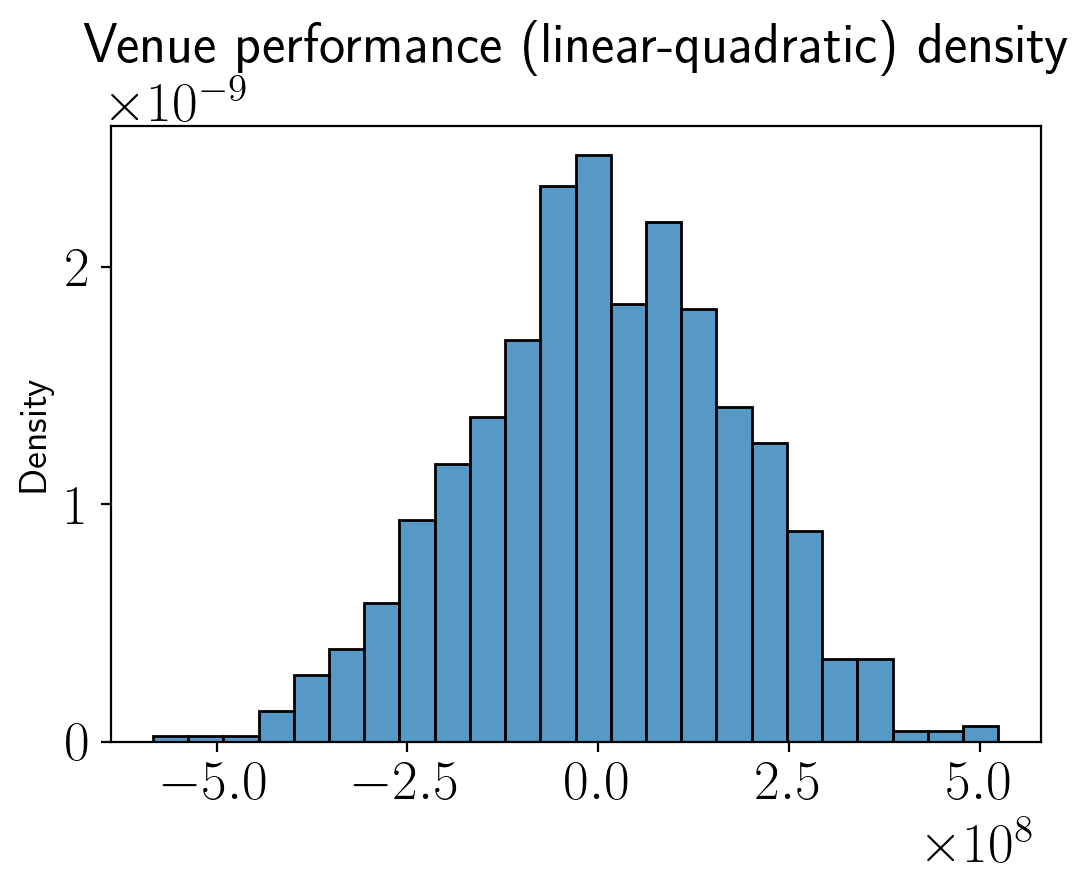

Venue's expected performance (LQ utility): 6722171.18984


In [53]:
sns.histplot(venue_wealth[0,:], stat='density')
plt.title("Venue performance (linear-quadratic) density")
plt.show()

print(f'Venue\'s expected performance (LQ utility): {venue_wealth[0,:].mean():1.5f}')

# Venue doesn't give reward

In [54]:
np.random.seed(100)

nsims = 1_000
strag_LP = '1'
strag_vn = '0'

S, Y, Z, X, nu, wealth, perf, rew, venue_wealth = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = False)

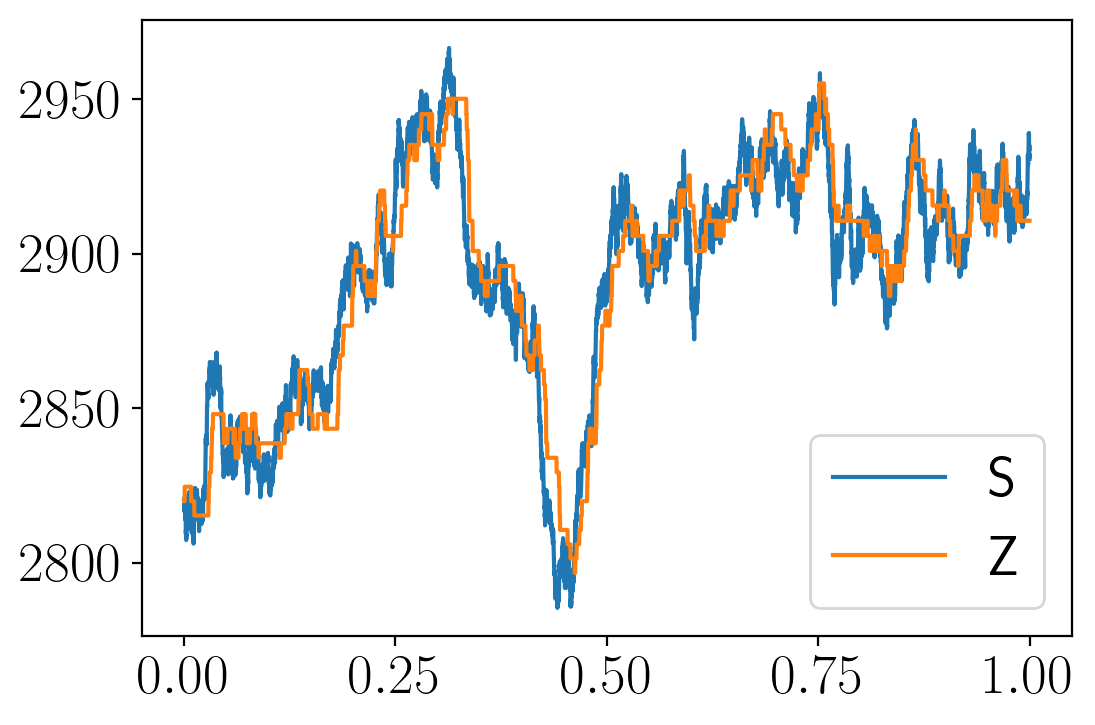

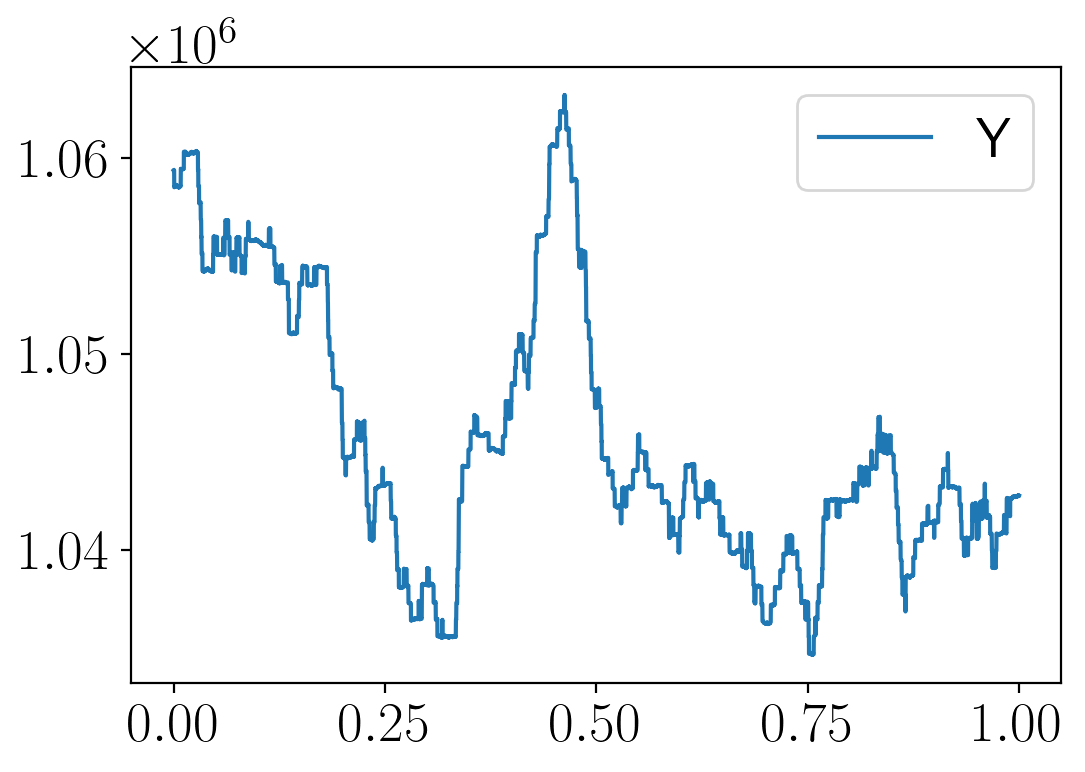

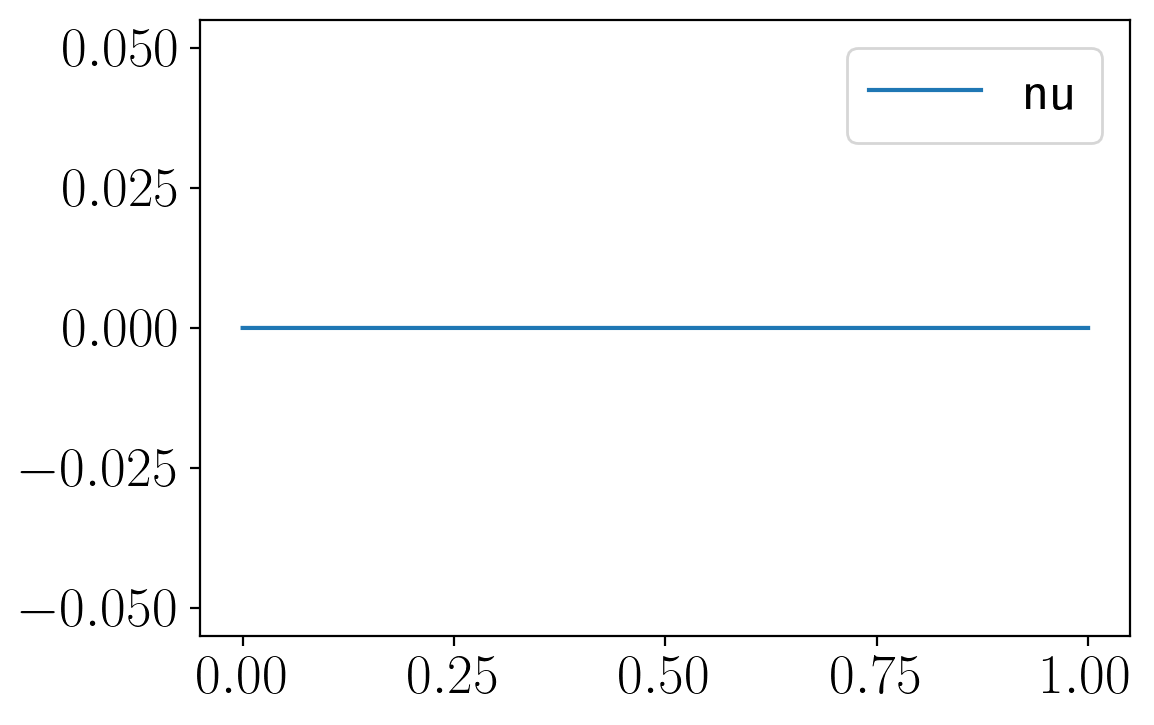

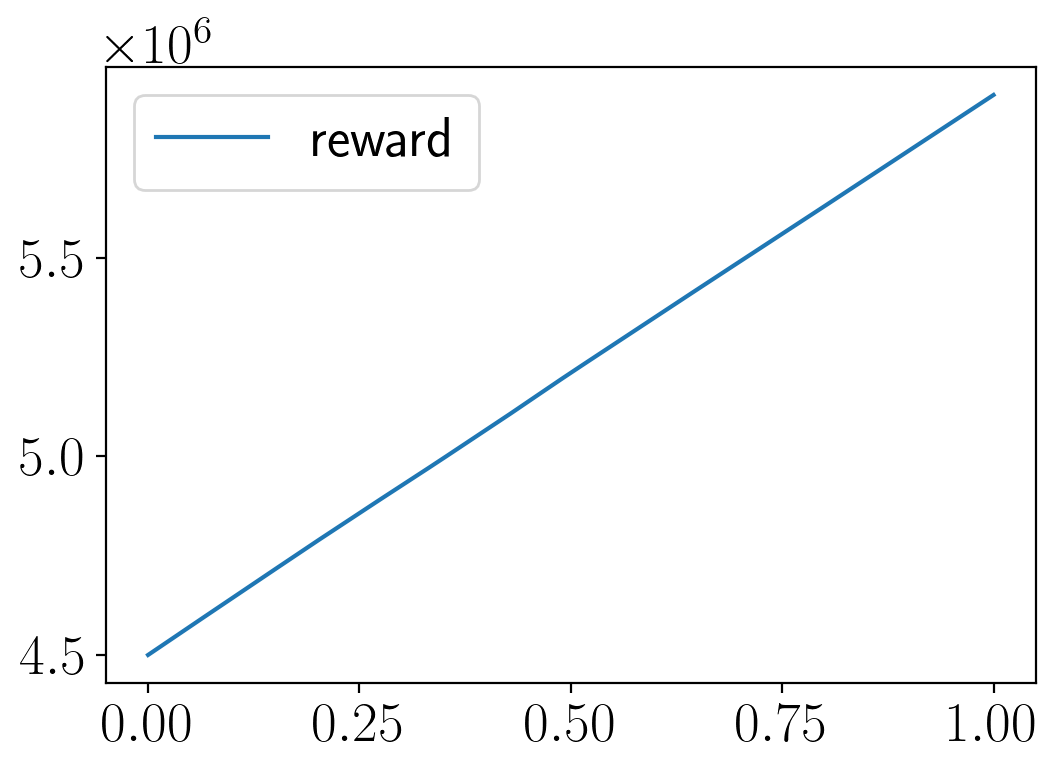

In [55]:
num_sim = 58

plt.plot(env.timesteps, S[:,num_sim], label='S')
plt.plot(env.timesteps, Z[:,num_sim], label='Z')
plt.legend()
plt.show()

plt.plot(env.timesteps, Y[:,num_sim], label='Y')
plt.legend()
plt.show()

plt.plot(env.timesteps, nu[:,num_sim], label='nu')
plt.legend()
plt.show()

plt.plot(env.timesteps, rew[:,num_sim], label='reward')
plt.legend()
plt.show()

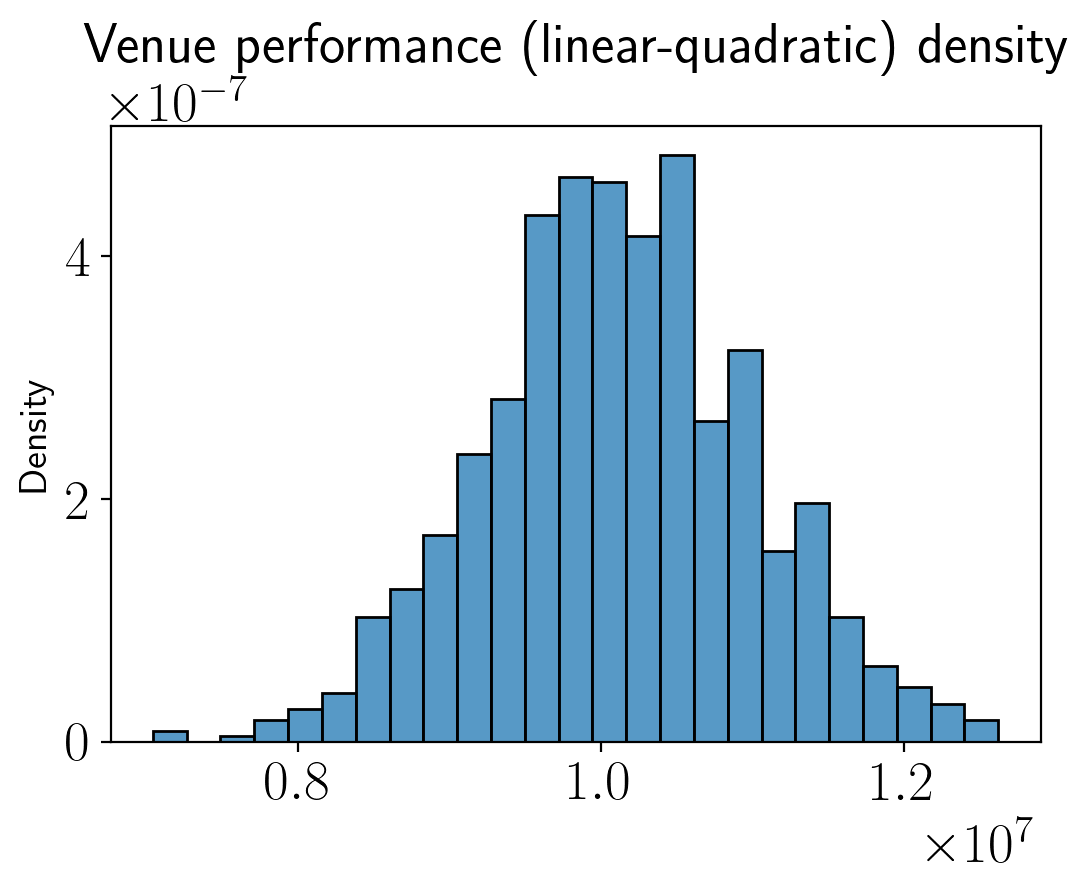

Venue's expected performance (LQ utility): 10116720.31891


In [56]:
sns.histplot(venue_wealth[0,:], stat='density')
plt.title("Venue performance (linear-quadratic) density")
plt.show()

print(f'Venue\'s expected performance (LQ utility): {venue_wealth[0,:].mean():1.5f}')